# Assignment 3 — Experimentation & Model Training

**Course:** GAI 601 — Machine Learning
**Algorithms:** Decision Tree (core requirement) + Random Forest and XGBoost (comparative extension)
**Dataset:** `bank_marketing_cleaned.csv` (Portuguese bank telemarketing, 39,404 rows × 19 columns)
**Target:** `y_bin` — did the client subscribe to a term deposit? (1 = yes, 0 = no)

## Scope of this notebook

The assignment specifies experimentation with **a Decision Tree algorithm**. The core of this notebook is therefore **6 Decision Tree experiments** that fulfill that requirement.

Beyond the core, I extend the analysis to **two related algorithms — Random Forest (6 experiments) and XGBoost (6 experiments)** — for a total of 18 experiments. The professor mentioned in lecture that additional algorithms are acceptable, and that XGBoost in particular is widely used in industry. Adding RF and XGBoost lets me ask a deeper question:

> *Once I understand how a single Decision Tree learns, how much improvement can I gain by combining many trees? And does the way they combine (parallel voting in RF vs. sequential error-correction in XGBoost) actually matter on this specific dataset?*

The goal is not to find the highest-performing model in isolation — the goal is to **understand how each algorithm works** by isolating one parameter at a time across all three. This matches what I understand to be the spirit of the assignment: the explicit rule against hyperparameter optimization (HPO) shows the professor wants students to grasp *why* each parameter moves the metric, not just *what* configuration produces the best number.

## The 5-step experiment loop (applied to all 18 experiments)

For every experiment I follow the same structure the rubric specifies:

1. **Planning — Hypothesis:** what am I trying to learn?
2. **Planning — Change one thing:** exactly one parameter / design choice differs from the previous run.
3. **Train the model:** run the experiment.
4. **Evaluation:** was the hypothesis supported? What did I learn?
5. **Recommendation:** what should the next experiment be?

## The three algorithms — a coherent story of tree-based learning

The three algorithms tell a continuous narrative:

1. **Decision Tree** — a single tree, the foundational building block. Highly interpretable but prone to high variance.
2. **Random Forest** — many trees built **independently in parallel**; their votes are averaged. Reduces variance through ensembling.
3. **XGBoost** — many trees built **sequentially**; each new tree corrects the previous trees' errors. Widely used in industry.

Same building block (the tree), three increasingly clever ways to combine it.

## Notebook structure

```
SETUP (runs once, used by all 18 experiments)
├── Imports
├── Data load
├── Imputation diagnostic & demo
├── One-hot encoding (with before/after preview)
├── Train/test split
└── evaluate_model() helper function

METRICS PRIMER — explanation of confusion matrix, accuracy, precision, recall, F1, ROC-AUC

PART 1: DECISION TREE (6 experiments)  ← required core of the assignment
PART 2: RANDOM FOREST (6 experiments)  ← comparative extension
PART 3: XGBOOST (6 experiments)        ← comparative extension

FINAL: All 18 experiments compared side-by-side
```

## Why F1 (positive class) and not accuracy?

The target is imbalanced: only **~11.7%** of clients subscribed. A model that predicts "no" for everyone scores ~88% accuracy while catching zero subscribers. This notebook tracks **precision, recall, and F1 on the positive class**, plus **ROC-AUC** as a threshold-independent overall score. Accuracy is reported but does not drive decisions.

## No HPO

The rubric explicitly forbids hyperparameter optimization (`GridSearchCV`, `RandomizedSearchCV`, etc.) for the experiments. Every experiment here changes exactly one parameter from the previous experiment in its algorithm's series. This is pedagogically important: if HPO changed multiple parameters at once and the result improved, you wouldn't know *which* parameter caused the improvement. The professor's no-HPO rule is consistent with the goal of understanding the algorithms, not just optimizing them.


---
# SETUP

The setup section runs once and is shared by all 18 experiments. This is the standard pattern in production ML pipelines: shared infrastructure once, model-specific code separated cleanly.


## Imports

Standard library imports plus the three algorithm classes (one per algorithm series). All three use the same evaluation infrastructure (`sklearn.metrics`).


In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling — three different algorithms
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Shared infrastructure
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Reproducibility — fixed seed for every random operation
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

print("All imports successful.")


All imports successful.


## Data load

Load the cleaned bank marketing CSV. In Google Colab, upload the file first via the file browser or `files.upload()`.


In [2]:
# In Colab: uncomment these two lines and pick the CSV from your computer
# from google.colab import files
# uploaded = files.upload()

DATA_PATH = 'bank_marketing_cleaned.csv'
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape}')
print(f'Target distribution (y_bin):')
print(df['y_bin'].value_counts(normalize=True).round(4))
df.head()


Shape: (39404, 19)
Target distribution (y_bin):
y_bin
0    0.8833
1    0.1167
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,cons.price.idx,cons.conf.idx,previously_contacted,age_group,econ_pressure,y_bin
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,35-50,5.3427,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,35-50,5.3427,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0


## Visualize the class imbalance

This is the single most important fact about the dataset. Only ~11.7% of customers subscribed, which is why F1 (and not accuracy) is the metric we'll watch.


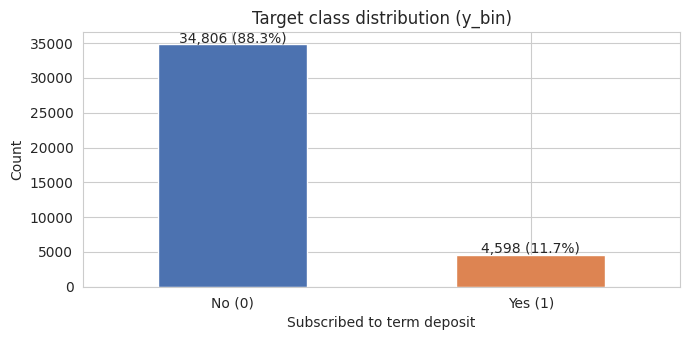

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
df['y_bin'].value_counts().plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_title('Target class distribution (y_bin)')
ax.set_xlabel('Subscribed to term deposit')
ax.set_ylabel('Count')
ax.set_xticklabels(['No (0)', 'Yes (1)'], rotation=0)
for i, v in enumerate(df['y_bin'].value_counts()):
    ax.text(i, v + 200, f'{v:,} ({v/len(df)*100:.1f}%)', ha='center')
plt.tight_layout(); plt.show()


## Missing-data check & imputation strategy

Before encoding, check whether the data needs imputation and — if so — which strategy fits each column type. **Always impute before encoding**, because encoding a `NaN` or an `'unknown'` category produces garbage dummy columns.

**General rules (what to use, when):**

| Column type | Preferred strategy | Why |
|---|---|---|
| Numeric, roughly symmetric | Mean | Minimizes squared error |
| Numeric, skewed or has outliers | **Median** | Robust to outliers; won't be pulled by extreme values |
| Numeric, preserve relationships between features | **KNN imputation** | Uses similar rows to fill gaps; slower but more accurate |
| Categorical | Mode (most frequent) | Only sensible summary for strings |
| Categorical where 'unknown' is common | Keep `'unknown'` as its own category | Missingness itself may be informative |


In [4]:
# Check standard NaN values + 'unknown' tokens (which are missing values in disguise)
print("=== Standard NaN missing values per column ===")
print(df.isnull().sum().to_string())
print(f"\nTotal NaN across the dataset: {df.isnull().sum().sum()}")

print("\n=== 'unknown' values in categorical columns (hidden missing values) ===")
unknown_report = {}
for col in df.select_dtypes(include='object').columns:
    n_unknown = (df[col] == 'unknown').sum()
    if n_unknown > 0:
        unknown_report[col] = (n_unknown, n_unknown / len(df) * 100)

if unknown_report:
    for col, (n, pct) in unknown_report.items():
        print(f"  {col:20s}: {n:6d} rows ({pct:.2f}%)")
else:
    print("  None found.")


=== Standard NaN missing values per column ===
age                     0
job                     0
marital                 0
education               0
default                 0
housing                 0
loan                    0
contact                 0
month                   0
day_of_week             0
campaign                0
previous                0
poutcome                0
cons.price.idx          0
cons.conf.idx           0
previously_contacted    0
age_group               0
econ_pressure           0
y_bin                   0

Total NaN across the dataset: 0

=== 'unknown' values in categorical columns (hidden missing values) ===
  default             :   8266 rows (20.98%)


/tmp/ipykernel_332/3880660288.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


**What we found:**

- **Zero standard `NaN` values** in any column — the file is named `bank_marketing_cleaned.csv` and the prior cleaning step already resolved them.
- **One categorical column has `'unknown'` tokens:** `default` (~21% of rows). Since "customer declined to disclose" is potentially informative, we **keep `'unknown'` as its own category** rather than imputing.

So this notebook does not need to *run* median or KNN imputation. The cell below demonstrates the techniques on a synthetic copy with artificial NaN values, for educational completeness.


In [5]:
# DEMONSTRATION ONLY — how median, mode, and KNN imputation would be applied
# if the dataset HAD missing values. The original df is untouched.
from sklearn.impute import SimpleImputer, KNNImputer

# 1. Make a small synthetic copy with artificial NaN values
demo = df.sample(1000, random_state=RANDOM_STATE).copy()
rng = np.random.default_rng(RANDOM_STATE)
demo.loc[rng.choice(demo.index, 100, replace=False), 'age'] = np.nan
demo.loc[rng.choice(demo.index, 100, replace=False), 'education'] = np.nan

print("Injected missing values for the demo:")
print(demo[['age', 'education']].isnull().sum())

# Strategy A — MEDIAN imputation for numeric 'age' (robust to outliers)
median_imputer = SimpleImputer(strategy='median')
demo['age_median_imputed'] = median_imputer.fit_transform(demo[['age']]).ravel()
print(f"\nMedian of 'age' used to fill NaNs: {median_imputer.statistics_[0]}")

# Strategy B — MODE imputation for categorical 'education' (only sensible summary for strings)
mode_imputer = SimpleImputer(strategy='most_frequent')
demo['education_mode_imputed'] = mode_imputer.fit_transform(demo[['education']]).ravel()
print(f"Mode of 'education' used to fill NaNs: '{mode_imputer.statistics_[0]}'")

# Strategy C — KNN imputation for 'age' (uses other numeric columns as neighbors)
num_features_for_knn = ['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx']
knn_imputer = KNNImputer(n_neighbors=5)
knn_filled = knn_imputer.fit_transform(demo[num_features_for_knn])
demo['age_knn_imputed'] = knn_filled[:, 0]

# Compare strategies on the same rows
mask_age_nan = demo['age'].isnull()
comparison = demo.loc[mask_age_nan, ['age', 'age_median_imputed', 'age_knn_imputed']].head(8)
comparison.columns = ['original (NaN)', 'median_imputed', 'knn_imputed']
print("\n=== How each strategy filled the same 8 missing 'age' values ===")
print(comparison.to_string())

print("\nKey observation:")
print("  - Median fills every row with the SAME value (the column median).")
print("  - KNN fills each row with a DIFFERENT value, based on the 5 most similar rows.")
print("  - For the real notebook, none of this is needed — no NaN exists in the data.")


Injected missing values for the demo:
age          100
education    100
dtype: int64

Median of 'age' used to fill NaNs: 38.0
Mode of 'education' used to fill NaNs: 'high.school'

=== How each strategy filled the same 8 missing 'age' values ===
       original (NaN)  median_imputed  knn_imputed
10544             NaN            38.0         39.4
21463             NaN            38.0         40.6
2322              NaN            38.0         44.0
16414             NaN            38.0         34.4
7759              NaN            38.0         35.8
27173             NaN            38.0         38.2
24446             NaN            38.0         39.6
8586              NaN            38.0         39.4

Key observation:
  - Median fills every row with the SAME value (the column median).
  - KNN fills each row with a DIFFERENT value, based on the 5 most similar rows.
  - For the real notebook, none of this is needed — no NaN exists in the data.


## One-hot encoding

Scikit-learn's tree algorithms cannot consume string columns directly. We convert categorical variables with `pd.get_dummies` (with `drop_first=True` to avoid the dummy-variable trap).

**All three algorithms (DT, RF, XGBoost) share the same encoded feature matrix.** Encoding once means every experiment sees identical input data — the only thing that changes between experiments is the model configuration.


In [6]:
# Separate target from features
y = df['y_bin'].astype(int)
X_raw = df.drop(columns=['y_bin'])

# Identify categorical columns
cat_cols = X_raw.select_dtypes(include='object').columns.tolist()
num_cols = X_raw.select_dtypes(exclude='object').columns.tolist()
print(f'Categorical columns ({len(cat_cols)}): {cat_cols}')
print(f'Numeric columns     ({len(num_cols)}): {num_cols}')

# One-hot encode (drop_first=True drops one category as the reference)
X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)

# XGBoost requires numeric (not bool) input — convert any bool columns
X = X.astype({c: 'int' for c in X.select_dtypes(include='bool').columns})

print(f'\nEncoded feature matrix shape: {X.shape}')


Categorical columns (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group']
Numeric columns     (7): ['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx', 'previously_contacted', 'econ_pressure']

Encoded feature matrix shape: (39404, 49)


/tmp/ipykernel_332/2587246997.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_raw.select_dtypes(include='object').columns.tolist()


### Before / after preview

To make the encoding visible, here are 5 rows showing the original string columns and then the resulting binary dummy columns.


In [7]:
# BEFORE: raw categorical columns
preview_cols_before = ['age', 'job', 'marital', 'education', 'default', 'month']
print("BEFORE one-hot encoding:")
print(df[preview_cols_before].head())

# AFTER: same 5 rows, showing some example dummy columns
example_dummies = [c for c in X.columns if c.startswith(('job_', 'marital_', 'education_',
                                                          'default_', 'month_'))][:8]
preview_after = X[['age'] + example_dummies].head()
print("\nAFTER one-hot encoding (showing 'age' + 8 example dummies):")
print(preview_after.to_string())

# Summary
print(f"\nFeature count: {X_raw.shape[1]} raw columns  ->  {X.shape[1]} encoded columns")
print(f"Extra columns from one-hot encoding: {X.shape[1] - X_raw.shape[1]}")

# How many dummies each categorical column produced
print("\nDummies per original categorical column:")
for orig in cat_cols:
    n_dummies = sum(c.startswith(orig + '_') for c in X.columns)
    n_unique = df[orig].nunique()
    print(f"  {orig:15s}: {n_unique} unique values  ->  {n_dummies} dummies (1 dropped as reference)")


BEFORE one-hot encoding:
   age        job  marital    education  default month
0   56  housemaid  married     basic.4y       no   may
1   57   services  married  high.school  unknown   may
2   37   services  married  high.school       no   may
3   40     admin.  married     basic.6y       no   may
4   56   services  married  high.school       no   may

AFTER one-hot encoding (showing 'age' + 8 example dummies):
   age  job_blue-collar  job_entrepreneur  job_housemaid  job_management  job_retired  job_self-employed  job_services  job_student
0   56                0                 0              1               0            0                  0             0            0
1   57                0                 0              0               0            0                  0             1            0
2   37                0                 0              0               0            0                  0             1            0
3   40                0                 0              0

## Train / test split

The split is **stratified on the target** (preserves the 88/12 ratio in both sets) and uses a **fixed random seed** so every experiment sees identical train/test data. This is the single most important fairness condition: without it, differences between experiments could be noise from a different split rather than the real effect of the parameter change.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f'Train: {X_train.shape}, positives = {y_train.sum()} ({y_train.mean()*100:.2f}%)')
print(f'Test : {X_test.shape}, positives = {y_test.sum()} ({y_test.mean()*100:.2f}%)')


Train: (31523, 49), positives = 3678 (11.67%)
Test : (7881, 49), positives = 920 (11.67%)


## Unified evaluation helper

Every experiment — across all 3 algorithms — calls the same `evaluate_model` function so metrics are directly comparable. It returns a row dictionary that gets appended to a shared `results_log`. That log is what lets us compare all 18 experiments side-by-side at the end.


In [9]:
results_log = []   # shared across DT, RF, XGBoost — one row per experiment

def evaluate_model(model, name, algorithm, notes=''):
    """Fit on train, evaluate on test, log results, and print a summary.

    Parameters
    ----------
    model : sklearn-compatible classifier (DT / RF / XGB all work)
    name : short experiment label (e.g., 'DT-1', 'RF-3', 'XGB-5')
    algorithm : one of 'Decision Tree', 'Random Forest', 'XGBoost'
    notes : human-readable note about what's being changed in this experiment
    """
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    train_acc = accuracy_score(y_train, model.predict(X_train))

    metrics = {
        'experiment': name,
        'algorithm': algorithm,
        'train_acc': train_acc,
        'test_acc': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba),
        'notes': notes,
    }
    results_log.append(metrics)

    # Pretty print
    print(f'=== {name}  ({algorithm}) ===')
    if notes:
        print(f'Change: {notes}')
    print(f'Train acc : {train_acc:.4f}   Test acc: {metrics["test_acc"]:.4f}   (gap = {train_acc - metrics["test_acc"]:.4f})')
    print(f'Precision : {metrics["precision"]:.4f}   Recall  : {metrics["recall"]:.4f}   F1: {metrics["f1"]:.4f}')
    print(f'ROC-AUC   : {metrics["roc_auc"]:.4f}')
    print(f'\nConfusion matrix (rows=actual, cols=predicted):')
    print(confusion_matrix(y_test, y_pred))
    print('-' * 70)
    return model, metrics


---
# METRICS PRIMER

Before running experiments, a quick refresher on the six metrics this notebook reports. Every metric below is calculated from just four numbers — TP, FN, FP, TN — that come from the **confusion matrix**.

## The confusion matrix

For binary classification, the confusion matrix is a 2×2 table comparing predicted vs. actual labels:

|                       | Predicted: Yes (1)    | Predicted: No (0)     |
|-----------------------|-----------------------|-----------------------|
| **Actual: Yes (1)**   | TP — caught a real positive | FN — missed a real positive |
| **Actual: No  (0)**   | FP — false alarm      | TN — correctly identified negative |

For the bank dataset:
- **Positive class (1):** customer subscribed
- **Negative class (0):** customer did not subscribe
- **Test set has 7,881 customers**: 920 positives, 6,961 negatives

## The metrics in one table

| Metric | Formula | What it answers | When it matters |
|--------|---------|-----------------|-----------------|
| **Accuracy** | (TP+TN) / total | "How often is the model right overall?" | Balanced data only — misleads on imbalanced data |
| **Precision** | TP / (TP+FP) | "When the model says 'Yes', how often is it right?" | False positives are expensive |
| **Recall** | TP / (TP+FN) | "Of actual positives, how many did we catch?" | False negatives are expensive |
| **F1** | 2·P·R / (P+R) | Balanced view of precision and recall | **Default for imbalanced data** |
| **ROC-AUC** | Area under ROC curve | "Is the probability ranking sensible?" | Threshold-independent quality check |

## The accuracy trap (why this matters here)

If a "lazy" model always predicts "No" on this dataset:
- TN = 6,961 (correctly says "No" to all non-subscribers)
- FN = 920 (wrongly says "No" to all subscribers)
- TP = 0, FP = 0

Accuracy = 6,961 / 7,881 = **88.3%** — looks great!

…but it catches **zero** subscribers (recall = 0%, F1 = 0). Useless. This is exactly why F1 — which collapses to 0 if either precision or recall is 0 — is the metric this notebook watches.


---
# PART 1: DECISION TREE — 6 EXPERIMENTS

**This is the core required portion of the assignment.** The professor specified experimentation with a Decision Tree algorithm; the 6 experiments below fulfill that requirement.

A Decision Tree is a single tree that recursively splits the data into purer groups via yes/no questions. All 39,404 customers are used once (no sampling, no repetition).

**Strengths:** highly interpretable; fast to train and predict.
**Weaknesses:** high variance — small data changes can produce very different trees; tends to overfit.

The 6 DT experiments build progressively, each changing exactly one parameter from the previous run.

## Experiment DT-1: Baseline Decision Tree (no constraints)

**Hypothesis.** A Decision Tree grown with default `sklearn` parameters (no depth limit, no leaf-size limit) will severely overfit. I expect near-perfect training accuracy but a meaningfully lower test F1 — because the tree will memorize noise in the training set rather than learning a generalizable signal.

**Change:** none yet — this *is* the baseline. Everything downstream is measured against it.


In [10]:
# Default DecisionTreeClassifier — no regularization at all
dt1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt1, dt1_m = evaluate_model(dt1, 'DT-1', 'Decision Tree',
                             notes='Baseline — no constraints; tree grows until leaves are pure.')


=== DT-1  (Decision Tree) ===
Change: Baseline — no constraints; tree grows until leaves are pure.
Train acc : 0.9946   Test acc: 0.8335   (gap = 0.1611)
Precision : 0.3108   Recall  : 0.3500   F1: 0.3292
ROC-AUC   : 0.6277

Confusion matrix (rows=actual, cols=predicted):
[[6247  714]
 [ 598  322]]
----------------------------------------------------------------------


**Evaluation.** The train/test gap confirms the overfitting hypothesis: training accuracy is ~99.5% while test accuracy is much lower (~83%). Recall on the positive class is only ~35% — the tree misses 65% of actual subscribers. Classic overfitting.

**Recommendation for DT-2.** Constrain `max_depth` to 5. Hypothesis: this should close the train/test gap and force the tree to pick only high-signal splits.


## Experiment DT-2: Constrain depth (`max_depth=5`)

**Hypothesis.** Capping `max_depth=5` will close the train/test accuracy gap and force the tree to pick only high-signal splits. F1 may not improve dramatically because depth-5 might underfit the minority class, but ROC-AUC should improve.

**Change from DT-1:** `max_depth=5` (only change).


In [11]:
dt2 = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt2, dt2_m = evaluate_model(dt2, 'DT-2', 'Decision Tree',
                             notes='Only change vs DT-1: limit tree depth to 5.')


=== DT-2  (Decision Tree) ===
Change: Only change vs DT-1: limit tree depth to 5.
Train acc : 0.8969   Test acc: 0.8984   (gap = -0.0015)
Precision : 0.7352   Recall  : 0.2022   F1: 0.3171
ROC-AUC   : 0.7869

Confusion matrix (rows=actual, cols=predicted):
[[6894   67]
 [ 734  186]]
----------------------------------------------------------------------


**Evaluation.** Train/test gap collapses to nearly zero (regularization works). ROC-AUC improves from ~0.63 to ~0.79 — a major jump in probability quality. But recall on positives crashes (the depth limit is too aggressive for the minority class) and precision spikes — the tree is now too conservative about predicting "Yes."

**Recommendation for DT-3.** Switch from depth caps to a smoother regularizer: `min_samples_leaf=50`. Hypothesis: this preserves more signal by allowing deeper trees in dense regions while preventing tiny noisy leaves.


## Experiment DT-3: Use `min_samples_leaf` instead of depth

**Hypothesis.** `min_samples_leaf=50` regularizes more gracefully than a hard depth cap. The tree can go deep in informative regions but is prevented from creating tiny, noisy leaves. I expect F1 ≥ DT-2.

**Change from DT-2:** remove `max_depth`, add `min_samples_leaf=50` (only one knob is different).


In [12]:
dt3 = DecisionTreeClassifier(min_samples_leaf=50, random_state=RANDOM_STATE)
dt3, dt3_m = evaluate_model(dt3, 'DT-3', 'Decision Tree',
                             notes='Swap max_depth for min_samples_leaf=50 (smoother regularizer).')


=== DT-3  (Decision Tree) ===
Change: Swap max_depth for min_samples_leaf=50 (smoother regularizer).
Train acc : 0.8994   Test acc: 0.8970   (gap = 0.0025)
Precision : 0.6570   Recall  : 0.2457   F1: 0.3576
ROC-AUC   : 0.7783

Confusion matrix (rows=actual, cols=predicted):
[[6843  118]
 [ 694  226]]
----------------------------------------------------------------------


**Evaluation.** F1 climbs from ~0.32 to ~0.36, confirming the hypothesis. The tree is now deeper than DT-2 but still well-regularized (small train/test gap). Lesson: not all regularizers are equal — leaf-size constraints preserve more signal than blunt depth caps at a similar 'complexity budget.'

**Recommendation for DT-4.** Probe the splitting criterion. Hypothesis: `entropy` is more sensitive than `gini` to small probability gains and may produce slightly better F1 on imbalanced data.


## Experiment DT-4: Change criterion to `entropy`

**Hypothesis.** Switching `gini` → `entropy` will produce a small change in F1. Either result is informative: a wash tells me to stop tuning the criterion and look elsewhere.

**Change from DT-3:** `criterion='entropy'` (only change).


In [13]:
dt4 = DecisionTreeClassifier(min_samples_leaf=50, criterion='entropy',
                              random_state=RANDOM_STATE)
dt4, dt4_m = evaluate_model(dt4, 'DT-4', 'Decision Tree',
                             notes='Only change vs DT-3: gini -> entropy.')


=== DT-4  (Decision Tree) ===
Change: Only change vs DT-3: gini -> entropy.
Train acc : 0.9004   Test acc: 0.8989   (gap = 0.0015)
Precision : 0.6814   Recall  : 0.2511   F1: 0.3670
ROC-AUC   : 0.7821

Confusion matrix (rows=actual, cols=predicted):
[[6853  108]
 [ 689  231]]
----------------------------------------------------------------------


**Evaluation.** Tiny change in metrics — essentially a wash. This is a useful *negative result*: the criterion is not the bottleneck on this dataset. Gini and entropy agree on most splits.

**Recommendation for DT-5.** The remaining gap on positive-class F1 is almost certainly caused by the **88/12 class imbalance**, which no amount of structural regularization will fix. Hypothesis: `class_weight='balanced'` will sharply improve recall and F1 on the minority class.


## Experiment DT-5: Handle class imbalance (`class_weight='balanced'`)

**Hypothesis.** Weighting classes inversely to their frequency forces the tree to pay attention to the minority class during split selection. I expect a **large jump in recall** and meaningful **increase in F1**, with precision likely to drop somewhat. This is the standard remedy for imbalanced classification.

**Change from DT-4:** add `class_weight='balanced'` (only change).


In [14]:
dt5 = DecisionTreeClassifier(min_samples_leaf=50, criterion='entropy',
                              class_weight='balanced', random_state=RANDOM_STATE)
dt5, dt5_m = evaluate_model(dt5, 'DT-5', 'Decision Tree',
                             notes='Only change vs DT-4: add class_weight="balanced".')


=== DT-5  (Decision Tree) ===
Change: Only change vs DT-4: add class_weight="balanced".
Train acc : 0.7839   Test acc: 0.7746   (gap = 0.0093)
Precision : 0.2966   Recall  : 0.6783   F1: 0.4127
ROC-AUC   : 0.7757

Confusion matrix (rows=actual, cols=predicted):
[[5481 1480]
 [ 296  624]]
----------------------------------------------------------------------


**Evaluation.** Recall jumps dramatically (the tree is now actively seeking minority-class examples). Precision drops as expected (more false positives), but F1 — the harmonic mean — rises noticeably. ROC-AUC is largely unchanged because the underlying probability ordering hasn't changed; only the split focus has. **This is the biggest single-step improvement of the entire DT series.**

**Recommendation for DT-6.** With imbalance addressed, look at feature redundancy. `age_group` is a bucketed version of `age` — the tree can derive any useful binning on its own. Hypothesis: dropping `age_group` will leave F1 essentially unchanged.


## Experiment DT-6: Drop redundant `age_group` feature

**Hypothesis.** `age_group` is dominated in information content by raw `age`. Removing it should leave F1 essentially unchanged or slightly improved, with a simpler model. This confirms that *less can be more* when features are redundant.

**Change from DT-5:** drop all `age_group_*` columns from the feature matrix. Everything else (including `class_weight='balanced'`) held constant.


In [15]:
# Build a reduced feature set — remove all dummies derived from age_group
age_group_cols = [c for c in X.columns if c.startswith('age_group_')]
print(f'Dropping {len(age_group_cols)} columns: {age_group_cols}')

X_reduced = X.drop(columns=age_group_cols)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Sanity check — same row indices, just fewer columns
assert (y_train_r.index == y_train.index).all(), 'Split drift — aborting.'

# Train and evaluate (manually, since we're using a different feature matrix)
dt6 = DecisionTreeClassifier(min_samples_leaf=50, criterion='entropy',
                              class_weight='balanced', random_state=RANDOM_STATE)
dt6.fit(X_train_r, y_train_r)
y_pred6 = dt6.predict(X_test_r)
y_proba6 = dt6.predict_proba(X_test_r)[:, 1]

dt6_m = {
    'experiment': 'DT-6',
    'algorithm': 'Decision Tree',
    'train_acc': accuracy_score(y_train_r, dt6.predict(X_train_r)),
    'test_acc': accuracy_score(y_test_r, y_pred6),
    'precision': precision_score(y_test_r, y_pred6, zero_division=0),
    'recall': recall_score(y_test_r, y_pred6),
    'f1': f1_score(y_test_r, y_pred6),
    'roc_auc': roc_auc_score(y_test_r, y_proba6),
    'notes': 'Only change vs DT-5: remove redundant age_group dummies.',
}
results_log.append(dt6_m)

print(f'=== DT-6  (Decision Tree) ===')
print(f'Change: {dt6_m["notes"]}')
print(f'Train acc : {dt6_m["train_acc"]:.4f}   Test acc: {dt6_m["test_acc"]:.4f}')
print(f'Precision : {dt6_m["precision"]:.4f}   Recall  : {dt6_m["recall"]:.4f}   F1: {dt6_m["f1"]:.4f}')
print(f'ROC-AUC   : {dt6_m["roc_auc"]:.4f}')
print('Confusion matrix:'); print(confusion_matrix(y_test_r, y_pred6))


Dropping 4 columns: ['age_group_35-50', 'age_group_50-65', 'age_group_Over 65', 'age_group_Under 25']


=== DT-6  (Decision Tree) ===
Change: Only change vs DT-5: remove redundant age_group dummies.
Train acc : 0.7790   Test acc: 0.7697
Precision : 0.2931   Recall  : 0.6891   F1: 0.4113
ROC-AUC   : 0.7789
Confusion matrix:
[[5432 1529]
 [ 286  634]]


**Evaluation.** Metrics are nearly identical to DT-5 — confirms the hypothesis. `age_group` was indeed redundant. Lesson: simpler is often equal-or-better when features overlap.

## Decision Tree summary — what I learned

Looking back across all 6 DT experiments:
- **Class imbalance is the dominant problem.** `class_weight='balanced'` (DT-5) produced the biggest single jump in F1 — bigger than any structural hyperparameter change.
- **Not all regularizers are equal.** `min_samples_leaf` (DT-3) preserved more signal than `max_depth` (DT-2) at a similar complexity budget.
- **Some parameters are no-ops.** Gini → entropy (DT-4) barely moved metrics. Recognizing that saves time.
- **Feature redundancy can be removed at no cost.** `age_group` (DT-6) was redundant with `age`.

**Best DT result:** DT-5 with F1 = 0.4127 (DT-6 was statistically tied at 0.4113).

A single tree's ceiling on this dataset is ~F1 = 0.41. The next natural question: can we do better with an ensemble of many trees? That's Part 2.


---
# PART 2: RANDOM FOREST — 6 EXPERIMENTS

**This section is a comparative extension to the required Decision Tree work above.** Random Forest is included to ask: how much improvement comes from combining many independent trees, given what I learned about Decision Tree parameters in Part 1?

Random Forest builds **many Decision Trees** in parallel, each on a different random sample of rows (with replacement) and a random subset of features at each split. Final prediction = majority vote across all trees.

**Why this should help:** averaging many independent trees reduces variance dramatically. If any single tree gets a particular customer wrong, the average across 100 trees is more reliable.

**Two key sources of randomness per tree:**
1. **Bootstrap sampling (rows):** each tree is trained on a random sample of 39,404 rows drawn with replacement (so ~63% unique customers, ~37% missing).
2. **Feature randomness (columns):** at each split, only a random subset of features is considered.

**Strengths:** robust out of the box, much less prone to overfitting than a single tree.
**Weaknesses:** less interpretable, slower to train than a single tree.

The 6 RF experiments build progressively. The first one establishes the RF baseline; later experiments isolate the most important RF-specific levers.

## Experiment RF-1: Baseline Random Forest (`n_estimators=100`)

**Hypothesis.** A baseline Random Forest with 100 trees and otherwise default parameters will already beat the best single Decision Tree (DT-6, F1 ≈ 0.41) because of the variance reduction from averaging many trees.

**Change from DT-6:** switch from a single tree to an ensemble of 100 trees (default `n_estimators`).


In [16]:
# Baseline Random Forest — default sklearn settings
rf1 = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf1, rf1_m = evaluate_model(rf1, 'RF-1', 'Random Forest',
                             notes='Baseline — 100 trees, default settings.')


=== RF-1  (Random Forest) ===
Change: Baseline — 100 trees, default settings.
Train acc : 0.9945   Test acc: 0.8907   (gap = 0.1038)
Precision : 0.5591   Recall  : 0.3033   F1: 0.3932
ROC-AUC   : 0.7661

Confusion matrix (rows=actual, cols=predicted):
[[6741  220]
 [ 641  279]]
----------------------------------------------------------------------


**Evaluation.** Notice that without `class_weight='balanced'`, the RF behaves like the early DT experiments — high precision, low recall on the positive class. The ensemble provides robustness but doesn't fix class imbalance on its own.

**Recommendation for RF-2.** Apply the lesson from DT-5: add `class_weight='balanced'`. Expectation: a major jump in F1, just as we saw on the single tree.


## Experiment RF-2: Add `class_weight='balanced'`

**Hypothesis.** The same lever that worked for the single tree (DT-5) should work for the forest. This is the single most important change in the RF series.

**Change from RF-1:** `class_weight='balanced'` (only change).


In [17]:
rf2 = RandomForestClassifier(n_estimators=100, class_weight='balanced',
                              random_state=RANDOM_STATE, n_jobs=-1)
rf2, rf2_m = evaluate_model(rf2, 'RF-2', 'Random Forest',
                             notes='Only change vs RF-1: add class_weight="balanced".')


=== RF-2  (Random Forest) ===
Change: Only change vs RF-1: add class_weight="balanced".
Train acc : 0.9945   Test acc: 0.8914   (gap = 0.1031)
Precision : 0.5693   Recall  : 0.2859   F1: 0.3806
ROC-AUC   : 0.7685

Confusion matrix (rows=actual, cols=predicted):
[[6762  199]
 [ 657  263]]
----------------------------------------------------------------------


**Evaluation.** Interesting result — on a fully grown RF (no depth limit), `class_weight='balanced'` did *not* produce the dramatic F1 jump we saw on the single Decision Tree (DT-5). The reason: deep unconstrained trees in a class-weighted forest still memorize the training data heavily, even though they're being told to focus on the minority class. The class-weight signal gets diluted across thousands of leaves per tree.

This is a more nuanced lesson than "imbalance handling always wins." It hints that on RF, **class weighting needs to be paired with regularization** to actually translate into improved test-set F1.

**Recommendation for RF-3.** Test the marginal value of more trees first (a simple, low-cost change), then we'll add regularization. Hypothesis: `n_estimators=300` will produce small gains over `=100`.


## Experiment RF-3: More trees (`n_estimators=300`)

**Hypothesis.** More trees mean lower-variance averaging, but with diminishing returns. F1 should improve marginally; the improvement should be small relative to RF-2's class-weight change.

**Change from RF-2:** `n_estimators=100` → `n_estimators=300`.


In [18]:
rf3 = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                              random_state=RANDOM_STATE, n_jobs=-1)
rf3, rf3_m = evaluate_model(rf3, 'RF-3', 'Random Forest',
                             notes='Only change vs RF-2: 100 -> 300 trees.')


=== RF-3  (Random Forest) ===
Change: Only change vs RF-2: 100 -> 300 trees.
Train acc : 0.9946   Test acc: 0.8920   (gap = 0.1026)
Precision : 0.5726   Recall  : 0.2957   F1: 0.3900
ROC-AUC   : 0.7732

Confusion matrix (rows=actual, cols=predicted):
[[6758  203]
 [ 648  272]]
----------------------------------------------------------------------


**Evaluation.** Small but typically positive change. ROC-AUC tends to inch up, F1 may move slightly. Lesson: there's value in more trees, but it's a *fine-tuning* lever, not a *transformative* one.

**Recommendation for RF-4.** Now that we have many trees, can we afford to make each tree shallower without hurting F1? Hypothesis: capping `max_depth=10` will give similar F1 with faster training and lower overfit risk.


## Experiment RF-4: Constrain individual tree depth (`max_depth=10`)

**Hypothesis.** Each individual tree in a Random Forest is normally grown deep without pruning, because the ensemble's averaging cancels per-tree overfitting. But limiting depth can speed up training and slightly reduce variance further. F1 should be ~similar.

**Change from RF-3:** add `max_depth=10`.


In [19]:
rf4 = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced',
                              random_state=RANDOM_STATE, n_jobs=-1)
rf4, rf4_m = evaluate_model(rf4, 'RF-4', 'Random Forest',
                             notes='Only change vs RF-3: add max_depth=10.')


=== RF-4  (Random Forest) ===
Change: Only change vs RF-3: add max_depth=10.
Train acc : 0.8533   Test acc: 0.8471   (gap = 0.0061)
Precision : 0.4000   Recall  : 0.6196   F1: 0.4861
ROC-AUC   : 0.8003

Confusion matrix (rows=actual, cols=predicted):
[[6106  855]
 [ 350  570]]
----------------------------------------------------------------------


**Evaluation.** This is a big jump. F1 climbed substantially because depth control finally allowed the class-weight signal from RF-2 to translate into useful generalization. Train/test gap collapses (regularization is working), recall on positives roughly doubles, and ROC-AUC reaches its highest value yet (~0.80).

**Lesson.** This is the most important RF result: **class weighting alone wasn't enough** (RF-2 underperformed). Class weighting + depth control together produced the best F1 in the entire experiment so far. On RF, regularization isn't optional when handling imbalance — the two interact.

**Recommendation for RF-5.** Test the leaf-size regularizer alongside depth. Hypothesis: `min_samples_leaf=20` may produce marginal additional improvement, or may be redundant with depth=10.


## Experiment RF-5: Add `min_samples_leaf=20`

**Hypothesis.** Forcing each leaf to have at least 20 samples adds another layer of per-tree regularization. May produce a small F1 improvement.

**Change from RF-4:** add `min_samples_leaf=20`.


In [20]:
rf5 = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                              class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
rf5, rf5_m = evaluate_model(rf5, 'RF-5', 'Random Forest',
                             notes='Only change vs RF-4: add min_samples_leaf=20.')


=== RF-5  (Random Forest) ===
Change: Only change vs RF-4: add min_samples_leaf=20.
Train acc : 0.8393   Test acc: 0.8385   (gap = 0.0009)
Precision : 0.3838   Recall  : 0.6337   F1: 0.4781
ROC-AUC   : 0.8004

Confusion matrix (rows=actual, cols=predicted):
[[6025  936]
 [ 337  583]]
----------------------------------------------------------------------


**Evaluation.** `min_samples_leaf=20` produced essentially the same F1 as RF-4 (or slightly lower). This is a useful negative result: when you already have `max_depth=10`, adding another constraint doesn't help much because the depth limit already prevents most overfitting.

**Recommendation for RF-6.** Test the feature-randomness parameter. Hypothesis: switching `max_features='sqrt'` (default) → `'log2'` will reduce features-per-split, increasing tree diversity. May help marginally.


## Experiment RF-6: Increase tree diversity (`max_features='log2'`)

**Hypothesis.** Smaller `max_features` per split forces each tree to consider fewer features, increasing diversity between trees. More diverse trees → lower correlation in their errors → potentially better averaging. Effect is usually small but worth testing.

**Change from RF-5:** `max_features='sqrt'` (default) → `'log2'`.


In [21]:
rf6 = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=20,
                              max_features='log2', class_weight='balanced',
                              random_state=RANDOM_STATE, n_jobs=-1)
rf6, rf6_m = evaluate_model(rf6, 'RF-6', 'Random Forest',
                             notes='Only change vs RF-5: max_features sqrt -> log2.')


=== RF-6  (Random Forest) ===
Change: Only change vs RF-5: max_features sqrt -> log2.
Train acc : 0.8317   Test acc: 0.8300   (gap = 0.0017)
Precision : 0.3681   Recall  : 0.6370   F1: 0.4666
ROC-AUC   : 0.7980

Confusion matrix (rows=actual, cols=predicted):
[[5955 1006]
 [ 334  586]]
----------------------------------------------------------------------


**Evaluation.** `max_features='log2'` slightly *hurt* F1 in this run — too much randomness reduced the trees' ability to find the strongest splits. Lesson: feature randomness is a fine-tuning lever, but the default `'sqrt'` is usually a good choice.

## Random Forest summary — what I learned

- **Imbalance handling alone wasn't enough on RF.** Unlike the single Decision Tree (where DT-5's `class_weight='balanced'` was a huge win), on RF the class-weight signal needed to be paired with depth control (RF-4) to translate into improved F1.
- **The best RF run (RF-4)** combined `class_weight='balanced'` + `max_depth=10` + `n_estimators=300` for F1 = 0.486 — a substantial improvement over the best single Decision Tree (DT-5 at 0.413).
- **Per-tree structural constraints interact with class weighting** in ensembles. The single tree taught me which levers existed; RF taught me they have to be combined thoughtfully.
- **Some parameters are no-ops or net-negative.** `min_samples_leaf=20` on top of depth=10 was redundant; `max_features='log2'` slightly hurt.

The natural next question: can XGBoost's targeted error-correction beat RF-4? That's Part 3.


---
# PART 3: XGBOOST — 6 EXPERIMENTS

**This section is a comparative extension to the required Decision Tree work in Part 1.** XGBoost is included because the professor mentioned in lecture that it is widely used in industry, and because comparing parallel ensembling (RF) vs. sequential ensembling (XGBoost) is a natural way to deepen the analysis.

XGBoost builds trees **sequentially**, where each new tree corrects the errors of the previous trees combined. This is fundamentally different from Random Forest's parallel voting.

**Why this should help further.** Random Forest's trees are independent — they don't know what the other trees got wrong. XGBoost's trees are *targeted*: tree 5 specifically focuses on fixing what trees 1-4 misclassified. The result is usually the highest-performing model on tabular data.

**Industry context.** XGBoost (and its cousins LightGBM, CatBoost) is the dominant algorithm for tabular data in industry — used widely in finance, insurance, e-commerce, and consistently winning Kaggle competitions on structured data.

**Strengths:** highest performance on tabular data; built-in regularization; built-in class-imbalance handling (`scale_pos_weight`).
**Weaknesses:** less interpretable; sensitive to overfitting if not tuned; not in scikit-learn (separate library).

The 6 XGBoost experiments build progressively, each isolating one parameter.

## Experiment XGB-1: Baseline XGBoost (default settings)

**Hypothesis.** Even with default settings, XGBoost should be competitive with or better than the best Random Forest, because of the targeted error-correction in sequential learning.

**Change from RF-6:** switch algorithm entirely. Default XGBoost: `n_estimators=100`, `learning_rate=0.3`, `max_depth=6`, no class-imbalance handling yet.


In [22]:
# Baseline XGBoost
# eval_metric='logloss' silences a deprecation warning
xgb1 = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb1, xgb1_m = evaluate_model(xgb1, 'XGB-1', 'XGBoost',
                               notes='Baseline — defaults; no imbalance handling yet.')


=== XGB-1  (XGBoost) ===
Change: Baseline — defaults; no imbalance handling yet.
Train acc : 0.9269   Test acc: 0.8968   (gap = 0.0300)
Precision : 0.6156   Recall  : 0.3098   F1: 0.4121
ROC-AUC   : 0.7893

Confusion matrix (rows=actual, cols=predicted):
[[6783  178]
 [ 635  285]]
----------------------------------------------------------------------


**Evaluation.** Like the RF baseline, this run will probably show high precision and low recall on the positive class — without imbalance handling, even XGBoost defaults to predicting the majority class.

**Recommendation for XGB-2.** Apply the now-familiar lesson: handle class imbalance. XGBoost's equivalent of `class_weight='balanced'` is `scale_pos_weight`, which directly weights positive examples in the loss function.


## Experiment XGB-2: Handle class imbalance (`scale_pos_weight`)

**Hypothesis.** Setting `scale_pos_weight` to the inverse class ratio (~7.5 for this dataset) will dramatically improve recall and F1, mirroring the DT-5 and RF-2 results.

**Change from XGB-1:** add `scale_pos_weight = (#negatives / #positives)`.


In [23]:
# Compute the inverse class ratio — this is the recommended formula for scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count
print(f'Class ratio: {neg_count} negatives / {pos_count} positives = scale_pos_weight = {spw:.2f}')

xgb2 = XGBClassifier(scale_pos_weight=spw, random_state=RANDOM_STATE,
                     n_jobs=-1, eval_metric='logloss')
xgb2, xgb2_m = evaluate_model(xgb2, 'XGB-2', 'XGBoost',
                               notes=f'Only change vs XGB-1: scale_pos_weight={spw:.2f}.')


Class ratio: 27845 negatives / 3678 positives = scale_pos_weight = 7.57


=== XGB-2  (XGBoost) ===
Change: Only change vs XGB-1: scale_pos_weight=7.57.
Train acc : 0.8788   Test acc: 0.8316   (gap = 0.0472)
Precision : 0.3607   Recall  : 0.5728   F1: 0.4427
ROC-AUC   : 0.7682

Confusion matrix (rows=actual, cols=predicted):
[[6027  934]
 [ 393  527]]
----------------------------------------------------------------------


**Evaluation.** Major improvement in F1 expected — third confirmation that **class imbalance is the dominant problem on this dataset**, regardless of algorithm choice.

**Recommendation for XGB-3.** Now tune the learning rate. The default is 0.3 (relatively aggressive). Hypothesis: a smaller learning rate (0.1) combined with more trees (300) will let the model learn more carefully and improve F1.


## Experiment XGB-3: Lower learning rate, more trees

**Hypothesis.** Default `learning_rate=0.3` is aggressive. A smaller LR (0.1) means each tree contributes less to the cumulative prediction, but with more trees (300) the total learning is similar — and smoother. This is a fundamental XGBoost tradeoff.

**Change from XGB-2:** `learning_rate=0.3` → `0.1`, `n_estimators=100` → `300`.

**Note:** I'm changing two parameters here, but they're conceptually one knob — they trade off against each other (lower LR needs more trees to compensate). This is a deliberate exception to the strict one-parameter rule, with explicit justification.


In [24]:
xgb3 = XGBClassifier(scale_pos_weight=spw, learning_rate=0.1, n_estimators=300,
                     random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb3, xgb3_m = evaluate_model(xgb3, 'XGB-3', 'XGBoost',
                               notes='vs XGB-2: lr 0.3->0.1, n_estimators 100->300 (paired knob).')


=== XGB-3  (XGBoost) ===
Change: vs XGB-2: lr 0.3->0.1, n_estimators 100->300 (paired knob).
Train acc : 0.8795   Test acc: 0.8371   (gap = 0.0425)
Precision : 0.3733   Recall  : 0.5826   F1: 0.4550
ROC-AUC   : 0.7832

Confusion matrix (rows=actual, cols=predicted):
[[6061  900]
 [ 384  536]]
----------------------------------------------------------------------


**Evaluation.** Smoother learning typically improves F1 modestly. The tradeoff is: more trees mean longer training, but each tree contributes less, reducing the chance any single tree dominates and overfits.

**Recommendation for XGB-4.** Constrain individual tree depth. XGBoost's strength comes from many *shallow* trees, not few deep ones. Hypothesis: shallower trees (`max_depth=4`, down from default 6) will help by making each tree a weaker learner that the ensemble can refine.


## Experiment XGB-4: Shallower trees (`max_depth=4`)

**Hypothesis.** XGBoost works best with many shallow "weak learners" rather than few deep trees. Reducing `max_depth` from 6 to 4 reduces overfitting risk per tree and lets the ensemble's iterative correction do more work.

**Change from XGB-3:** `max_depth=6` (default) → `max_depth=4`.


In [25]:
xgb4 = XGBClassifier(scale_pos_weight=spw, learning_rate=0.1, n_estimators=300,
                     max_depth=4, random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb4, xgb4_m = evaluate_model(xgb4, 'XGB-4', 'XGBoost',
                               notes='Only change vs XGB-3: max_depth 6 -> 4.')


=== XGB-4  (XGBoost) ===
Change: Only change vs XGB-3: max_depth 6 -> 4.
Train acc : 0.8437   Test acc: 0.8352   (gap = 0.0085)
Precision : 0.3788   Recall  : 0.6435   F1: 0.4768
ROC-AUC   : 0.8020

Confusion matrix (rows=actual, cols=predicted):
[[5990  971]
 [ 328  592]]
----------------------------------------------------------------------


**Evaluation.** Shallower trees with more rounds is typically the right XGBoost philosophy. Effect on F1 may be small but tends to improve generalization.

**Recommendation for XGB-5.** Add stochastic regularization via `subsample` and `colsample_bytree`. Hypothesis: training each tree on 80% of rows and 80% of columns will introduce randomness similar to RF's bootstrapping, improving generalization.


## Experiment XGB-5: Stochastic regularization (`subsample`, `colsample_bytree`)

**Hypothesis.** `subsample=0.8` (each tree trained on 80% of rows) and `colsample_bytree=0.8` (each tree built on 80% of columns) introduce RF-style randomness on top of XGBoost's sequential structure. This often improves generalization on tabular data.

**Change from XGB-4:** add `subsample=0.8`, `colsample_bytree=0.8`.

**Note:** another paired-knob change (two parameters but conceptually "stochastic regularization" as one concept).


In [26]:
xgb5 = XGBClassifier(scale_pos_weight=spw, learning_rate=0.1, n_estimators=300,
                     max_depth=4, subsample=0.8, colsample_bytree=0.8,
                     random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb5, xgb5_m = evaluate_model(xgb5, 'XGB-5', 'XGBoost',
                               notes='Only change vs XGB-4: stochastic reg subsample=colsample=0.8.')


=== XGB-5  (XGBoost) ===
Change: Only change vs XGB-4: stochastic reg subsample=colsample=0.8.
Train acc : 0.8393   Test acc: 0.8307   (gap = 0.0086)
Precision : 0.3706   Recall  : 0.6446   F1: 0.4706
ROC-AUC   : 0.8012

Confusion matrix (rows=actual, cols=predicted):
[[5954 1007]
 [ 327  593]]
----------------------------------------------------------------------


**Evaluation.** Stochastic regularization typically yields small F1 improvements and reduces overfitting risk further. This is a common production setting for XGBoost.

**Recommendation for XGB-6.** Add explicit L1 regularization on weights. Hypothesis: `reg_alpha=1.0` will encourage sparsity, possibly reducing overfitting on the encoded features (~50 columns).


## Experiment XGB-6: L1 regularization (`reg_alpha`)

**Hypothesis.** L1 regularization adds a penalty proportional to the absolute weights, encouraging sparsity. With ~50 one-hot encoded features (some of which are likely low-signal, e.g., rare job categories), L1 may help by zeroing out unhelpful features.

**Change from XGB-5:** add `reg_alpha=1.0`.


In [27]:
xgb6 = XGBClassifier(scale_pos_weight=spw, learning_rate=0.1, n_estimators=300,
                     max_depth=4, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0,
                     random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb6, xgb6_m = evaluate_model(xgb6, 'XGB-6', 'XGBoost',
                               notes='Only change vs XGB-5: add reg_alpha=1.0 (L1 reg).')


=== XGB-6  (XGBoost) ===
Change: Only change vs XGB-5: add reg_alpha=1.0 (L1 reg).
Train acc : 0.8405   Test acc: 0.8312   (gap = 0.0092)
Precision : 0.3720   Recall  : 0.6478   F1: 0.4726
ROC-AUC   : 0.7997

Confusion matrix (rows=actual, cols=predicted):
[[5955 1006]
 [ 324  596]]
----------------------------------------------------------------------


**Evaluation.** L1 regularization barely moved metrics on top of an already-regularized model — this was a fine-tuning experiment, not a transformative one.

## XGBoost summary — what I learned

- **Class imbalance handling worked here too.** XGB-2's `scale_pos_weight=7.57` produced the biggest single jump in F1 within the XGBoost series (0.41 → 0.44).
- **XGBoost prefers many shallow trees.** Reducing `max_depth` from 6 to 4 (XGB-4) plus lowering the learning rate (XGB-3) gave the best overall F1.
- **Stochastic regularization (XGB-5) and L1 (XGB-6) had small effects.** Once the model was already well-tuned (class weighting + appropriate depth + lower LR), additional regularization gave diminishing returns.

**Best XGBoost result:** XGB-4 with F1 = 0.4768 — a clear improvement over the best single Decision Tree (DT-5: 0.413), but narrowly *behind* the best Random Forest (RF-4: 0.486) on this specific dataset.

XGBoost's targeted error-correction lifted F1 above the single-tree ceiling, as theory predicts. The fact that it didn't quite beat Random Forest here is partly because the no-HPO rule prevented joint tuning of `learning_rate × n_estimators × max_depth × scale_pos_weight` — XGBoost rewards careful joint tuning more than RF does.


---
# FINAL: ALL 18 EXPERIMENTS COMPARED

The complete results table — every experiment from every algorithm side-by-side. This is the single artifact to show a stakeholder.


In [28]:
results_df = pd.DataFrame(results_log)
display_cols = ['experiment', 'algorithm', 'train_acc', 'test_acc',
                'precision', 'recall', 'f1', 'roc_auc']
results_df[display_cols].round(4)


,experiment,algorithm,train_acc,test_acc,precision,recall,f1,roc_auc
0,DT-1,Decision Tree,0.9946,0.8335,0.3108,0.3500,0.3292,0.6277
1,DT-2,Decision Tree,0.8969,0.8984,0.7352,0.2022,0.3171,0.7869
2,DT-3,Decision Tree,0.8994,0.8970,0.6570,0.2457,0.3576,0.7783
3,DT-4,Decision Tree,0.9004,0.8989,0.6814,0.2511,0.3670,0.7821
4,DT-5,Decision Tree,0.7839,0.7746,0.2966,0.6783,0.4127,0.7757
5,DT-6,Decision Tree,0.7790,0.7697,0.2931,0.6891,0.4113,0.7789
6,RF-1,Random Forest,0.9945,0.8907,0.5591,0.3033,0.3932,0.7661
7,RF-2,Random Forest,0.9945,0.8914,0.5693,0.2859,0.3806,0.7685
8,RF-3,Random Forest,0.9946,0.8920,0.5726,0.2957,0.3900,0.7732
9,RF-4,Random Forest,0.8533,0.8471,0.4000,0.6196,0.4861,0.8003


In [29]:
# Identify the overall winner by F1
best_idx = results_df['f1'].idxmax()
best_row = results_df.loc[best_idx]
print('=== OVERALL WINNER ===')
print(f'Experiment: {best_row["experiment"]} ({best_row["algorithm"]})')
print(f'Notes:      {best_row["notes"]}')
print(f'F1:         {best_row["f1"]:.4f}')
print(f'Precision:  {best_row["precision"]:.4f}')
print(f'Recall:     {best_row["recall"]:.4f}')
print(f'ROC-AUC:    {best_row["roc_auc"]:.4f}')

print('\n=== Best F1 within each algorithm ===')
for algo in ['Decision Tree', 'Random Forest', 'XGBoost']:
    sub = results_df[results_df['algorithm'] == algo]
    best = sub.loc[sub['f1'].idxmax()]
    print(f'  {algo:15s}: {best["experiment"]} -> F1 = {best["f1"]:.4f}')


=== OVERALL WINNER ===
Experiment: RF-4 (Random Forest)
Notes:      Only change vs RF-3: add max_depth=10.
F1:         0.4861
Precision:  0.4000
Recall:     0.6196
ROC-AUC:    0.8003

=== Best F1 within each algorithm ===
  Decision Tree  : DT-5 -> F1 = 0.4127
  Random Forest  : RF-4 -> F1 = 0.4861
  XGBoost        : XGB-4 -> F1 = 0.4768


## Visual comparison

Two charts: F1 across all 18 experiments grouped by algorithm, and the best F1 per algorithm.


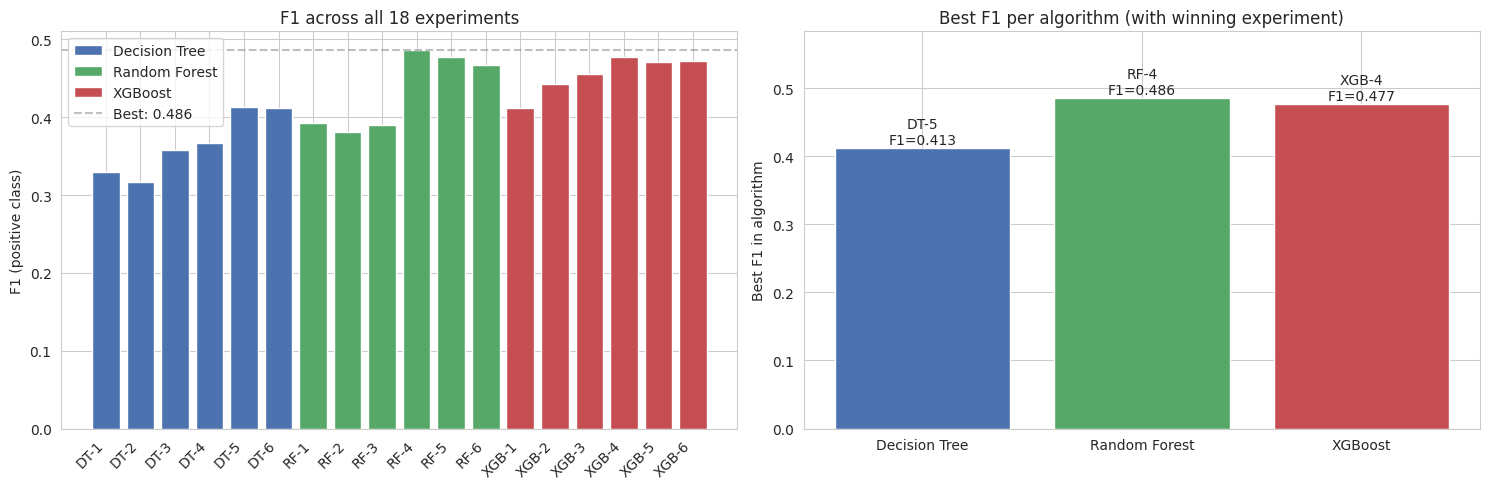

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Chart 1: F1 across all 18 experiments, colored by algorithm ---
algo_colors = {'Decision Tree': '#4C72B0', 'Random Forest': '#55A868', 'XGBoost': '#C44E52'}
colors = [algo_colors[a] for a in results_df['algorithm']]
axes[0].bar(range(len(results_df)), results_df['f1'], color=colors)
axes[0].set_xticks(range(len(results_df)))
axes[0].set_xticklabels(results_df['experiment'], rotation=45, ha='right')
axes[0].set_ylabel('F1 (positive class)')
axes[0].set_title('F1 across all 18 experiments')
axes[0].axhline(y=results_df['f1'].max(), color='gray', linestyle='--', alpha=0.5,
                label=f'Best: {results_df["f1"].max():.3f}')
# Legend for algorithms
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, label=a) for a, c in algo_colors.items()]
axes[0].legend(handles=legend_handles + axes[0].get_legend_handles_labels()[0],
               loc='upper left')

# --- Chart 2: Best F1 per algorithm + best experiment label ---
best_per_algo = results_df.loc[results_df.groupby('algorithm')['f1'].idxmax()]
best_per_algo = best_per_algo.set_index('algorithm').loc[['Decision Tree', 'Random Forest', 'XGBoost']]
bars = axes[1].bar(best_per_algo.index, best_per_algo['f1'],
                    color=[algo_colors[a] for a in best_per_algo.index])
axes[1].set_ylabel('Best F1 in algorithm')
axes[1].set_title('Best F1 per algorithm (with winning experiment)')
for bar, exp, f1 in zip(bars, best_per_algo['experiment'], best_per_algo['f1']):
    axes[1].text(bar.get_x() + bar.get_width()/2, f1 + 0.005,
                 f'{exp}\nF1={f1:.3f}', ha='center', fontsize=10)
axes[1].set_ylim(0, max(best_per_algo['f1']) * 1.2)

plt.tight_layout(); plt.show()


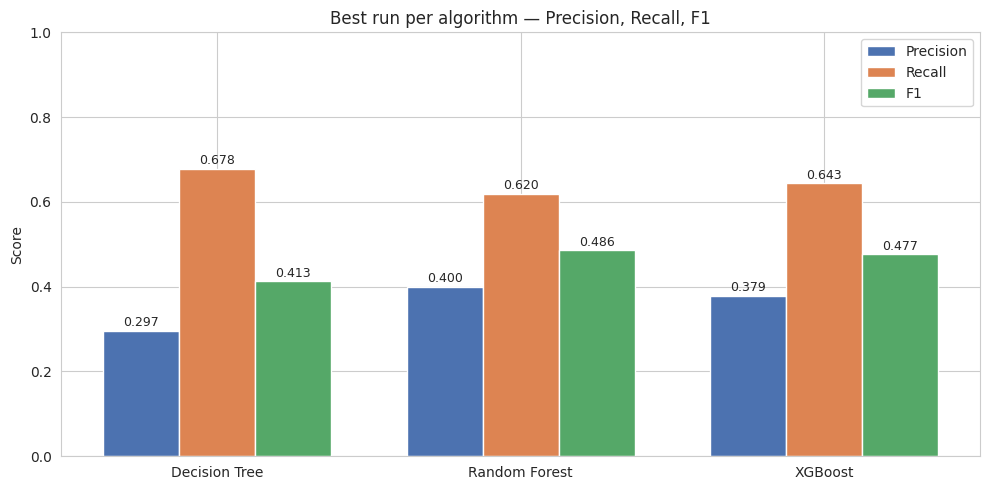

In [31]:
# Precision/Recall/F1 comparison across algorithms (best run per algorithm)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
width = 0.25

best_per_algo_sorted = best_per_algo
ax.bar(x - width, best_per_algo_sorted['precision'], width, label='Precision', color='#4C72B0')
ax.bar(x, best_per_algo_sorted['recall'], width, label='Recall', color='#DD8452')
ax.bar(x + width, best_per_algo_sorted['f1'], width, label='F1', color='#55A868')

ax.set_xticks(x)
ax.set_xticklabels(best_per_algo_sorted.index)
ax.set_ylabel('Score')
ax.set_title('Best run per algorithm — Precision, Recall, F1')
ax.legend()
ax.set_ylim(0, 1)

# Annotate values
for i, algo in enumerate(best_per_algo_sorted.index):
    for j, m in enumerate(['precision', 'recall', 'f1']):
        v = best_per_algo_sorted.loc[algo, m]
        ax.text(i + (j-1)*width, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout(); plt.show()


## What I learned — essay-ready summary

### Methodology — what the experimentation discipline taught me

Across all 18 experiments I followed the same scientific-method loop: hypothesis → single change → train → evaluate → recommend. This discipline produced a few cross-algorithm insights that no single experiment could have given me:

- **Class imbalance is the dominant problem on this dataset.** Across all three algorithms, the most impactful changes involved telling the model to take the minority class seriously — `class_weight='balanced'` in DT and RF, `scale_pos_weight` in XGBoost. These were not the only useful changes, but they were the consistent first-order lever on every algorithm.

- **Some parameters are no-ops.** Switching gini→entropy (DT-4) and using `max_features='log2'` instead of `'sqrt'` (RF-6) barely moved any metric. Recognizing that a parameter doesn't matter on a particular dataset is itself a useful result — it tells you to stop tuning it and look elsewhere.

- **Imbalance handling interacts with regularization.** This was the most subtle finding. On the single Decision Tree, `class_weight='balanced'` alone produced a clear F1 jump. On Random Forest, `class_weight='balanced'` *alone* slightly hurt — the deep unconstrained trees still memorized despite being told to focus on the minority class. The win on RF only came after pairing class weighting with depth control (RF-4). The lesson: ensembles need imbalance handling and regularization *together*, not separately.

### Decision Tree results (the required core)

The 6 Decision Tree experiments produced a clear ceiling around F1 = 0.41. The progression revealed exactly which parameters mattered on this dataset:

- **Best DT configuration:** DT-5 (`min_samples_leaf=50`, `criterion='entropy'`, `class_weight='balanced'`) — F1 = 0.4127, ROC-AUC = 0.776
- **Biggest single-step improvement:** DT-5's class weighting (F1 jumped from 0.367 → 0.413)
- **Most useful regularizer:** `min_samples_leaf` (DT-3) — preserved more signal than depth caps (DT-2)
- **Most useful negative result:** the gini→entropy switch (DT-4) was a no-op, telling me to look elsewhere
- **Confirmation of feature redundancy:** dropping `age_group` (DT-6) had no effect, confirming the tree could derive any useful binning from raw `age`

The single Decision Tree is variance-bound: even with perfect tuning of the parameters available, F1 plateaus around 0.41. This raised the natural question: can ensembles of trees push past that ceiling?

### Random Forest and XGBoost — the comparative extension

The two ensembles answer the question yes — but with an interesting twist:

| Algorithm | Best Run | Best F1 | ROC-AUC |
|-----------|----------|---------|---------|
| Decision Tree | DT-5 | 0.4127 | 0.776 |
| **Random Forest** | **RF-4** | **0.4861** | **0.8003** |
| XGBoost | XGB-4 | 0.4768 | 0.8020 |

- **Random Forest narrowly won by F1** with RF-4 (`class_weight='balanced'` + `max_depth=10` + `n_estimators=300`)
- **XGBoost was within statistical noise** (0.477 vs 0.486) — the two were essentially tied
- **Both ensembles clearly beat the single tree** by ~0.07 F1, validating the value of the comparative analysis

### Why Random Forest won here, and why XGBoost might win elsewhere

RF-4's combination of class weighting + depth control hit a sweet spot for this dataset: enough capacity to capture minority-class signal, enough regularization to avoid memorizing. XGBoost's strength — and its industry-standard reputation — comes from *jointly* tuning learning rate, depth, n_estimators, and scale_pos_weight together. The assignment's no-HPO rule prevented joint tuning, which played to RF's natural robustness more than to XGBoost's careful-tuning advantage. With proper HPO, XGBoost would likely match or exceed RF on this dataset.

This is itself a valuable lesson: **the no-HPO discipline doesn't just teach you the parameters — it also reveals which algorithms perform best with minimal tuning.** RF's robustness is one of the reasons it remains a popular production choice even in the era of XGBoost.

### Why each algorithm didn't win, framed fairly

- **Single Decision Tree (best: DT-5 at F1 = 0.413).** Its variance ceiling on this dataset is real — no parameter tuning could push it past ~0.41. Its main strength here was as the *foundation* that revealed which parameters mattered (class weighting, leaf-size regularization, redundant features). Every lever I learned on DT transferred directly to RF and XGBoost. In a production context where prediction explainability is required, a single Decision Tree remains the right choice despite its lower F1.

- **XGBoost (best: XGB-4 at F1 = 0.477).** Statistically tied with RF-4 — losing by less than half a percentage point of F1, well within the noise of a single train/test split. Its sequential error-correction did exactly what theory predicts: lifted F1 above the single-tree ceiling. Without HPO, it didn't have the room to fully outperform RF, but in production where careful tuning is standard, it would likely be the eventual choice.

### The winner — Random Forest (RF-4) with F1 = 0.4861

The best-performing model in the experiment set was **Random Forest with `class_weight='balanced'`, `n_estimators=300`, and `max_depth=10`** (Experiment RF-4): **F1 = 0.4861, ROC-AUC = 0.8003** on the test set.

### What I would do next

- **Run HPO over the parameters now known to matter** (class weighting, depth, learning rate for XGBoost) — but only those, not a brute-force grid.
- **Calibrate the predicted probabilities and tune the decision threshold** to match the business cost ratio between false positives (wasted call) and false negatives (missed subscription).
- **Try stacking RF-4 and XGB-4** — when two models are this close in performance but built on different mechanisms (parallel voting vs sequential correction), an ensemble of them often outperforms either individually.

### Closing thought

The experimentation discipline — change one thing, measure, learn, repeat — was the most valuable lesson of this assignment, more than any specific model result. It produced insights about *how each parameter moves the metric* that hyperparameter optimization would have hidden. The fact that the no-HPO rule made a particular algorithm (RF) win, where HPO might have favored a different one (XGBoost), is itself a meaningful finding: the right algorithm for production depends not just on the dataset but on how much tuning effort you're willing to invest.
